In [1]:
# 数据预处理：

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv("student-mat.csv", sep=";")
print("====数据集基本信息====")
print(df.info())
print("\n====描述性统计====")
print(df.describe())

print("\n====缺失值统计====")
print(df.isnull().sum())
df = df.dropna() #删除缺失样本
df = df.drop_duplicates() #删除重复行
#G3期末成绩范围0~20，过滤异常
df = df[(df["G3"]>=0)&(df["G3"]<=20)]

#0-1转换
df_encode = pd.get_dummies(df,drop_first=True)

====数据集基本信息====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object

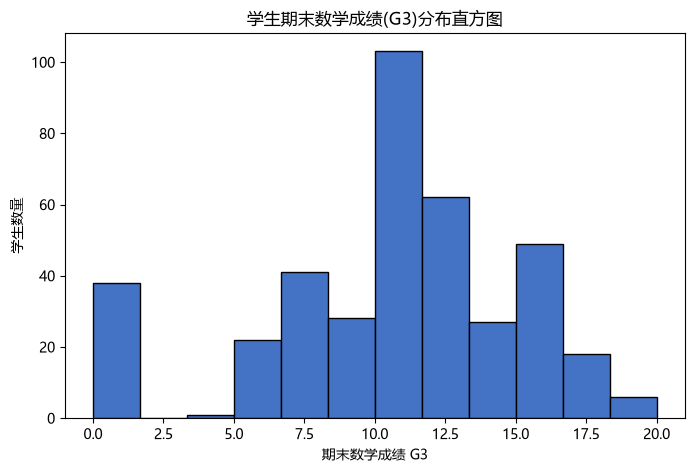

In [2]:
# 学生期末成绩可视化（G3分布直方图）：

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

#3 可视化：期末成绩G3分布直方图
plt.figure(figsize=(8,5))
plt.hist(df["G3"],bins=12,edgecolor="black",color="#4472C4")
plt.xlabel("期末数学成绩 G3")
plt.ylabel("学生数量")
plt.title("学生期末数学成绩(G3)分布直方图")
plt.savefig("G3_hist.png",dpi=300,bbox_inches="tight")
plt.show()

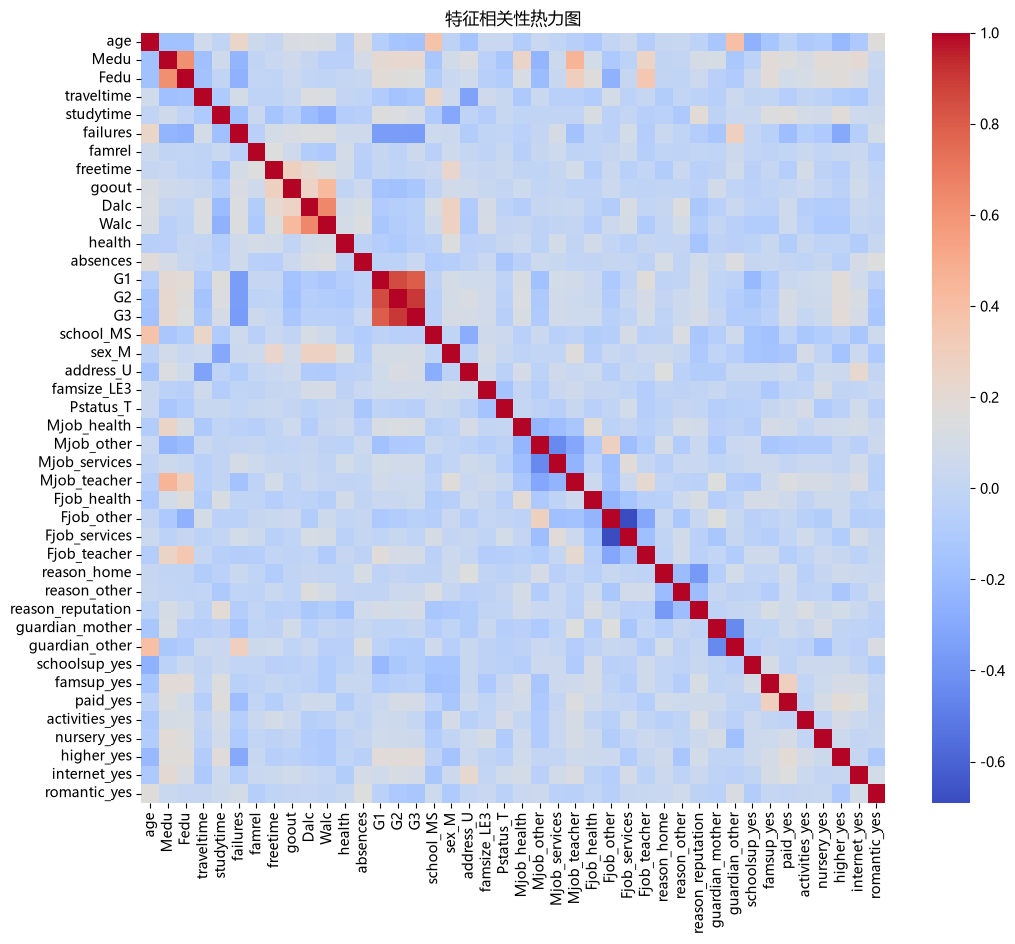

In [3]:
# 特征相关分析（热力图）：

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

#热力图 相关系数
corr = df_encode.corr()
plt.figure(figsize=(12,10))
sns.heatmap(corr,annot=False,cmap="coolwarm")
plt.title("特征相关性热力图")
plt.savefig("heatmap.png",dpi=300,bbox_inches="tight")
plt.show()

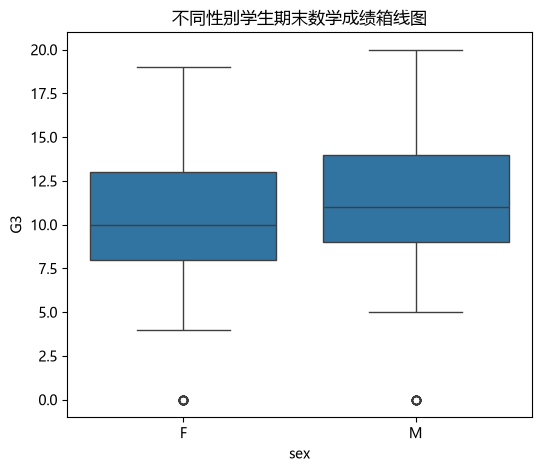

In [4]:
# 男女学生期末成绩对比（箱线图）：

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

#箱线图：男女期末成绩G3对比
plt.figure(figsize=(6,5))
sns.boxplot(x="sex",y="G3",data=df)
plt.title("不同性别学生期末数学成绩箱线图")
plt.savefig("sex_box.png",dpi=300,bbox_inches="tight")
plt.show()

In [5]:
# 随机森林挖掘模型（G3期末成绩）：

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

#4 随机森林挖掘模型，目标：G3期末成绩
X = df_encode.drop("G3",axis=1)
y = df_encode["G3"]
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

rf = RandomForestRegressor(random_state=42)
rf.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [6]:
# 重要影响特征排序：

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

#输出特征重要度
feature_import = pd.DataFrame({
    "feature":X.columns,
    "importance":rf.feature_importances_
}).sort_values("importance",ascending=False)

print("\n====特征重要性排序（影响期末成绩G3的因素）====")
print(feature_import.head(10))


====特征重要性排序（影响期末成绩G3的因素）====
           feature  importance
14              G2    0.793254
12        absences    0.110093
28     reason_home    0.021086
0              age    0.010433
13              G1    0.005979
6           famrel    0.005260
8            goout    0.004840
11          health    0.004190
36  activities_yes    0.003933
4        studytime    0.003697


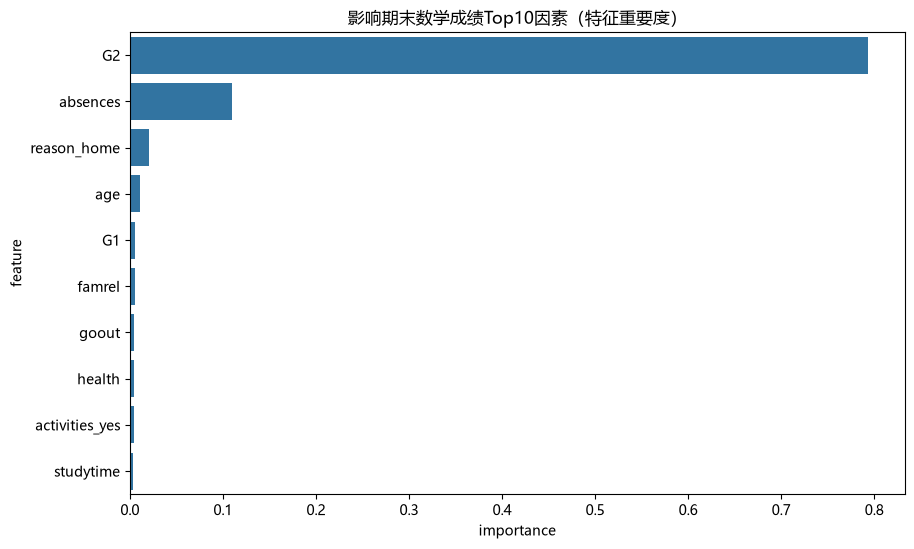

In [7]:
# 前十对期末数学成绩重要特征（柱状图）：

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

#绘制前10个最重要特征柱状图
plt.figure(figsize=(10,6))
top10 = feature_import.head(10)
sns.barplot(x="importance",y="feature",data=top10)
plt.title("影响期末数学成绩Top10因素（特征重要度）")
plt.savefig("feature_import.png",dpi=300,bbox_inches="tight")
plt.show()